# **FDA Regulations and Hospial Quality of Service Correlation Analysis**
By: Alyce Fawole and Aarchi Rana

[link text](https://github.com/AlyceFawole/AlyceFawole.git)

Link to GitHub Website

## ***Collobaration Plan***

We met in person three times, setup a public Github to
work on, and used a shared Collab Notebook which was then downloaded by one of us to be converted into html. Our first session was a planning day to establish a collective question and find an appropriate data source. Our following two sessions were used to select our exact data sets, extract the data, transform it, and then load said data.

##***Preliminary Research Question and Plan***

For our project we were interested in US Healthcare and patient risks. Looking into this we started investigating medical device usage and patient care quality in the US. To do this one of the datasets we decided to use was Medical Device Recalls (https://github.com/AlyceFawole/AlyceFawole/blob/main/Medical_Device_Recalls_Updated.xlsx)
which contains FDA Medical Device Recall Records from 2024 to the early October 2026 data. This dataset will be useful for our question because this is our data to directly analyze FDA regulations since these records are coming directly from the FDA and contain specifics on which medical devices do not meet FDA regulation standards. We also plan to use another dataset to measure Healthcare institution performance and/or efficiancy in patient care. Currently, we are trying to work with Compilcations and Death - Hospital level data (https://github.com/AlyceFawole/AlyceFawole/blob/main/Complications_and_Deaths-Hospital.csv) which contains data from HCUP on patient post-care complications and post-care mortality within 30 days as well as the PSI overall scores and contributing subcategory scores for each Hospital in the dataset. This dataset was chosen to give us measurable data on service provided by healthcare institutions that we intended to link and/or analyse together with said healthcare institutions FDA compliance via a connection with our Medical Device Recall dataset and the medical devices used at said healthcare institutions. We still need an additional dataset to create a clear link between the two datasets we have now. As of right now, we have a dataset directly on healthcare performace on a institution level and another dataset directly on FDA regulations sepcifically on which medical devices failed these regulations on a National level. We will need another dataset to provide the connection between national medical devices and institution level usuage for a stronger analysis. With our current data are connections are mostly broad, but we can still analyse correlations between overal healthcare performance in specific areas and the FDA failures for medical devices in those specific areas.

**Primary Guiding Question:** Does failures to comply with FDA regulations in medical devices affect quality of service given by healthcare instituions?

##***Data Tidying***

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
%cd /content
!git clone https://github.com/AlyceFawole/AlyceFawole.git

Mounted at /content/drive
/content
Cloning into 'AlyceFawole'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 9 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 1.15 MiB | 6.43 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [ ]:

import pandas as pd

df_recalls = pd.read_excel('/content/AlyceFawole/Medical_Device_Recalls_Updated.xlsx')
df_recalls.head()

#this cell shows file upload confirmation; this file was downloaded, then uploaded from excel

,Medical Device Recalls and Early Alerts | FDA,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,Date,Issue,Product Area,Status
1,10/09/2026,Early Alert: Diagnostic Ultrasound System Issu...,Diagnostic Ultrasound,Early Alert – FDA collecting information
2,10/05/2026,IV Tubing Set Correction: ICU Medical Updates ...,IV Tubing Set,Recall Confirmed
3,10/05/2026,"Infusion Set Recall: BD and CareFusion 303, In...",Infusion Set,Recall Confirmed
4,10/02/2026,Breathing Circuit Recall: Draeger Removes Vent...,Breathing Circuit,Recall Confirmed


In [ ]:
import pandas as pd

# Loading the FDA medical device recalls spreadsheet
df_recalls = pd.read_excel('/content/AlyceFawole/Medical_Device_Recalls_Updated.xlsx', header=1)

# Standardize column names: remove extra whitespace, make lowercase, and replace spaces with underscores
df_recalls.columns = df_recalls.columns.str.strip().str.lower().str.replace(' ', '_')

display(df_recalls.dtypes)
df_recalls

,0
date,object
issue,object
product_area,object
status,object


,date,issue,product_area,status
0,10/09/2026,Early Alert: Diagnostic Ultrasound System Issu...,Diagnostic Ultrasound,Early Alert – FDA collecting information
1,10/05/2026,IV Tubing Set Correction: ICU Medical Updates ...,IV Tubing Set,Recall Confirmed
2,10/05/2026,"Infusion Set Recall: BD and CareFusion 303, In...",Infusion Set,Recall Confirmed
3,10/02/2026,Breathing Circuit Recall: Draeger Removes Vent...,Breathing Circuit,Recall Confirmed
4,09/25/2026,Angiographic Catheter Recall: Boston Scientifi...,Angiographic Catheter,Recall Confirmed
...,...,...,...,...
188,01/31/2025,Update to Alert: Infusion Pump Issue from Fres...,Infusion Pumps,Recall Confirmed
189,01/30/2025,Glucose and Glucose/Ketone Meter Correction: N...,Glucose Strip/Meter,Recall Confirmed
190,12/20/2024,Infusion Pump Battery Recall: ICU Medical Remo...,Infusion Pumps,Recall Confirmed
191,12/18/2024,Catheter Correction: Boston Scientific Updates...,Balloon Catheter,Recall Confirmed


In [ ]:
#Converting date column into the correct pandas data type
df_recalls['date'] = pd.to_datetime(df_recalls['date'], format='%m/%d/%Y')

# Store these columns as categories since they have a limited set of repeated values
df_recalls['product_area'] = df_recalls['product_area'].astype('category')
df_recalls['status'] = df_recalls['status'].astype('category')

#Separating exact date in date time format into separate month & year columns for easier data summarization
df_recalls['year'] = df_recalls['date'].dt.year
df_recalls['month'] = df_recalls['date'].dt.month_name()


display(df_recalls.dtypes)
df_recalls

#This is the data behind all the FDA recalls in between the years of 2024-2026(most recent), in medical devices only. We sorted through this data, and removed cells which contained "outpatient only" devices, to limit our set to recalls from within hospital settings.
#It was found on the official FDA website, under the dection "Medical Device Recalls and Early Alerts"

,0
date,datetime64[ns]
issue,object
product_area,category
status,category
year,int32
month,object


,date,issue,product_area,status,year,month
0,2026-10-09,Early Alert: Diagnostic Ultrasound System Issu...,Diagnostic Ultrasound,Early Alert – FDA collecting information,2026,October
1,2026-10-05,IV Tubing Set Correction: ICU Medical Updates ...,IV Tubing Set,Recall Confirmed,2026,October
2,2026-10-05,"Infusion Set Recall: BD and CareFusion 303, In...",Infusion Set,Recall Confirmed,2026,October
3,2026-10-02,Breathing Circuit Recall: Draeger Removes Vent...,Breathing Circuit,Recall Confirmed,2026,October
4,2026-09-25,Angiographic Catheter Recall: Boston Scientifi...,Angiographic Catheter,Recall Confirmed,2026,September
...,...,...,...,...,...,...
188,2025-01-31,Update to Alert: Infusion Pump Issue from Fres...,Infusion Pumps,Recall Confirmed,2025,January
189,2025-01-30,Glucose and Glucose/Ketone Meter Correction: N...,Glucose Strip/Meter,Recall Confirmed,2025,January
190,2024-12-20,Infusion Pump Battery Recall: ICU Medical Remo...,Infusion Pumps,Recall Confirmed,2024,December
191,2024-12-18,Catheter Correction: Boston Scientific Updates...,Balloon Catheter,Recall Confirmed,2024,December


In [ ]:
df_recalls.dtypes

,0
date,datetime64[ns]
issue,object
product_area,category
status,category
year,int32
month,object


This shows that our data is being correctly recognized as appropriate data types by pandas

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, '2026 Oct'),
  Text(1, 0, '2026 Sep'),
  Text(2, 0, '2026 Aug'),
  Text(3, 0, '2026 Jul'),
  Text(4, 0, '2026 Jun'),
  Text(5, 0, '2026 May'),
  Text(6, 0, '2026 Apr'),
  Text(7, 0, '2026 Mar'),
  Text(8, 0, '2026 Feb'),
  Text(9, 0, '2026 Jan'),
  Text(10, 0, '2025 Dec'),
  Text(11, 0, '2025 Nov'),
  Text(12, 0, '2025 Oct'),
  Text(13, 0, '2025 Sep'),
  Text(14, 0, '2025 Aug'),
  Text(15, 0, '2025 Jul'),
  Text(16, 0, '2025 Jun'),
  Text(17, 0, '2025 May'),
  Text(18, 0, '2025 Apr'),
  Text(19, 0, '2025 Mar'),
  Text(20, 0, '2025 Feb'),
  Text(21, 0, '2025 Jan'),
  Text(22, 0, '2024 Dec')])

<Figure size 1600x600 with 0 Axes>

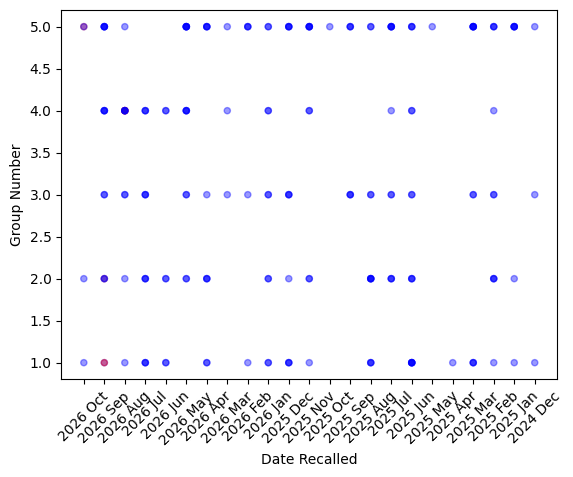

In [ ]:
import matplotlib.pyplot as plt

df_recalls["Date Recalled"] = df_recalls["year"].astype(str) + " " + df_recalls['date'].dt.strftime('%b')


# This area is shrinking our data into legible criterias, which display the devices into categories.
def group_area(area):
    area = str(area).lower()
    if "pump" in area or "infusion" in area or "administration set" in area:
        return "Infusion"
    elif "ventilat" in area or "breathing" in area or "resuscitat" in area or "anesthe" in area:
        return "Respiratory/Anesthesia"
    elif "catheter" in area or "cannula" in area or "stent" in area or "graft" in area:
        return "Catheters/Vascular"
    elif "kit" in area or "pack" in area or "tray" in area:
        return "Kits"
    else:
        return "Other"

df_recalls["Group"] = df_recalls["product_area"].astype(str).map(group_area)

# This is affecting the y-axis, we divided common categories into numerical values
df_recalls["Group Number"] = df_recalls["Group"].map({
    "Infusion": 1,
    "Respiratory/Anesthesia": 2,
    "Catheters/Vascular": 3,
    "Kits": 4,
    "Other": 5
})

# We colored our graph by color in status (similar to that in lab 6)
cols = df_recalls["status"].astype(str).map(
    lambda s: "red" if "Early" in s else "blue"
)

plt.figure(figsize=(16,6))
df_recalls.plot.scatter(x="Date Recalled", y="Group Number",
                        c=cols, alpha=.4)
plt.xticks(rotation=45)

#This scatterplot shows when recalls happened, across different device groups.
#This ties in with our research since we can use these categories & determine when recalls occured per category, and month/year. A dot references that there was an occurence atleast once that month.

In [ ]:
#After the changes made to produce our scatterplot we have to retidy full data table up (its redundant to have separate 'year' and 'month' columns AND a 'date' AND a 'Date Recalled' columns
df_recalls.drop(columns=['date'], inplace=True)
df_recalls.drop(columns=['year'], inplace=True)
df_recalls.drop(columns=['month'], inplace=True)
df_recalls

,issue,product_area,status,Date Recalled,Group,Group Number
0,Early Alert: Diagnostic Ultrasound System Issu...,Diagnostic Ultrasound,Early Alert – FDA collecting information,2026 Oct,Other,5
1,IV Tubing Set Correction: ICU Medical Updates ...,IV Tubing Set,Recall Confirmed,2026 Oct,Other,5
2,"Infusion Set Recall: BD and CareFusion 303, In...",Infusion Set,Recall Confirmed,2026 Oct,Infusion,1
3,Breathing Circuit Recall: Draeger Removes Vent...,Breathing Circuit,Recall Confirmed,2026 Oct,Respiratory/Anesthesia,2
4,Angiographic Catheter Recall: Boston Scientifi...,Angiographic Catheter,Recall Confirmed,2026 Sep,Catheters/Vascular,3
...,...,...,...,...,...,...
188,Update to Alert: Infusion Pump Issue from Fres...,Infusion Pumps,Recall Confirmed,2025 Jan,Infusion,1
189,Glucose and Glucose/Ketone Meter Correction: N...,Glucose Strip/Meter,Recall Confirmed,2025 Jan,Other,5
190,Infusion Pump Battery Recall: ICU Medical Remo...,Infusion Pumps,Recall Confirmed,2024 Dec,Infusion,1
191,Catheter Correction: Boston Scientific Updates...,Balloon Catheter,Recall Confirmed,2024 Dec,Catheters/Vascular,3


In [ ]:
#Reordering columns so data table has a more readable organized layout
df_recalls = df_recalls[['Date Recalled', 'issue', 'product_area', 'Group', 'Group Number', 'status']]
df_recalls

,Date Recalled,issue,product_area,Group,Group Number,status
0,2026 Oct,Early Alert: Diagnostic Ultrasound System Issu...,Diagnostic Ultrasound,Other,5,Early Alert – FDA collecting information
1,2026 Oct,IV Tubing Set Correction: ICU Medical Updates ...,IV Tubing Set,Other,5,Recall Confirmed
2,2026 Oct,"Infusion Set Recall: BD and CareFusion 303, In...",Infusion Set,Infusion,1,Recall Confirmed
3,2026 Oct,Breathing Circuit Recall: Draeger Removes Vent...,Breathing Circuit,Respiratory/Anesthesia,2,Recall Confirmed
4,2026 Sep,Angiographic Catheter Recall: Boston Scientifi...,Angiographic Catheter,Catheters/Vascular,3,Recall Confirmed
...,...,...,...,...,...,...
188,2025 Jan,Update to Alert: Infusion Pump Issue from Fres...,Infusion Pumps,Infusion,1,Recall Confirmed
189,2025 Jan,Glucose and Glucose/Ketone Meter Correction: N...,Glucose Strip/Meter,Other,5,Recall Confirmed
190,2024 Dec,Infusion Pump Battery Recall: ICU Medical Remo...,Infusion Pumps,Infusion,1,Recall Confirmed
191,2024 Dec,Catheter Correction: Boston Scientific Updates...,Balloon Catheter,Catheters/Vascular,3,Recall Confirmed


In [ ]:
df_recalls['Group Number'] = df_recalls['Group Number'].astype(str)
display(df_recalls.dtypes)

#This is done so that .describe will treat Group Number as an object for summary stats instead of numeric summary stats that wouldn't mean anything for our analysis
df_recalls['Group Number'] = df_recalls['Group Number'].astype(str)
display(df_recalls.dtypes)

df_recalls.describe()

,0
Date Recalled,object
issue,object
product_area,category
Group,object
Group Number,object
status,category


,Date Recalled,issue,product_area,Group,Group Number,status
count,193,193,193,193,193,193
unique,23,193,132,5,5,2
top,2026 Sep,Early Alert: Diagnostic Ultrasound System Issu...,Convenience Kit,Other,5,Recall Confirmed
freq,16,1,19,63,63,187


**EDA: **
(1):Based on our scatterplot, recalls occur in all five device groups throughout the time range we looked at. The broad “Other” category has recall activity in the most months, which is expected since it combines many device types. Among the specific groups, Infusion, Respiratory/Anesthesia, and Catheters/Vascular devices show recalls recurring at a similar, steady rate with only a few gaps, while Kits appear less often early on and then show up in consecutive months in mid-to-late 2026. (Each dot represents at least one recall in that month rather than a count of recalls, so this plot shows how consistently each group is affected over time, not how many recalls it had.)This relates back to our question because recalls in hospital-used devices are recurring and spread across several device types, which gives us a broad and steady set of data to work with.

(2)Other is the most common product area with around 23 occurences in total with the main product_area within Other being Convinence Kit. Infusion Pump comes next with 12 (16 if you count the 4 “Infusion Pump Software” entries), followed by Ventilator with 7. This matters for our question because kits and pumps are used constantly in hospitals. The recall titles also show that many kit recalls come from a single faulty component, such as recalled sodium chloride or lidocaine ampules, that ends up in many different kits. One bad part can therefore trigger recalls across many products, which helps explain why kits recur so often.

(3) 187 of the 193 entries (about 97%) are “Recall Confirmed,” and only 6 are early alerts. All 6 were issued between late August and October 2026. This matters because early alerts mean the FDA is still collecting information, so the most recent months may be incomplete or change later. Older data is more reliable than the newest data, which is something we can keep in mind while delving for more data supporting our question.


**Cited Source:**
Center for Devices and Radiological Health. (2026, September 25). Medical device recalls and early alerts. FDA. U.S. Food and Drug Administration. https://www.fda.gov/medical-devices/medical-device-safety/medical-device-recalls-and-early-alerts


In [ ]:
%%shell
jupyter nbconvert --to html /PATH/TO/YOUR/NOTEBOOKFILE.ipynb